# Practical 6: reading enhancers with a deep learning model

**ISN Neurochemistry School 2026**

Some regions of the genome are open in one cell type and closed in others, and
that is measurable. Knowing *where* such a region is does not say *why*. The sequence should carry the answer: a
region is open in a Kenyon cell because it contains motifs that Kenyon cell
transcription factors bind.

> Given only 500 nucleotides, can a model tell which cell type a region is open
> in, and which nucleotides did it use to decide?

The cell types are the same four as Practical 5: gamma and alpha/beta Kenyon
cells from the mushroom body, the fly's learning and memory centre; `T1`, a
neuron of the visual system; and astrocyte-like glia.

Nothing is trained here. The model is pretrained and each prediction takes
under a second on a laptop.

## Where this data comes from

Nothing here is our data, and the model was not trained by us.

| what | from | link |
|---|---|---|
| **DeepFlyBrain** model | Janssens et al. 2022, *Nature* 601:630 | via `crested.get_model`, <https://flybrain.aertslab.org> |
| adult brain ATAC tracks | Janssens et al. 2022 | <https://flybrain.aertslab.org/downloads/>, GEO GSE163697 |
| the 54 enhancers tested in flies | Janssens et al. 2022, Figure 4 | `downloads/other/enhancersTested.bed` at that portal |
| motif database | CREsted | via `crested.get_motif_db` |
| dm6 genome | UCSC | <https://hgdownload.soe.ucsc.edu/goldenPath/dm6/bigZips/> |

CREsted itself is Kempynck, De Winter et al. 2026, *Nature Methods*:
<https://crested.readthedocs.io>. `scripts/download_data.py` prints every URL as
it fetches, so you can trace any number back to its source. Please cite the
groups that published the data, not the course.

## Running on Google Colab

Run this cell first.

In [1]:
# Colab setup. On a laptop install this cell does nothing.
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    import os

    !pip install -q "crested[motif]" pyBigWig "pandas==2.2.3"

    # Get the course files, or update them if this session already has them.
    # Re-running this cell, or opening both practicals in one session, is fine.
    import subprocess

    if os.path.isdir("/content/course/.git"):
        # An update is refused if anything in that folder has been edited.
        # Stopping here would be unhelpful and discarding the edit silently
        # would be worse, so report it and carry on with what is already there.
        update = subprocess.run(
            ["git", "-C", "/content/course", "pull", "--quiet", "--ff-only"],
            capture_output=True, text=True,
        )
        if update.returncode:
            print("Could not update the course files. Continuing with the copy")
            print("already in this session, which is almost certainly fine.")
    else:
        !rm -rf /content/course
        !git clone -q https://github.com/nkempynck/isn-school-2026 /content/course
    %cd /content/course
    print("Ready.")
else:
    print("Running locally, nothing to install.")

Running locally, nothing to install.


## 0. Setup

Two environment variables must be set **before** anything is imported.
`KERAS_BACKEND` tells Keras to use PyTorch, and `KERAS_TORCH_DEVICE` keeps the
computation on the CPU.

In [2]:
import os

os.environ["KERAS_BACKEND"] = "torch"
os.environ["KERAS_TORCH_DEVICE"] = "cpu"

import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import crested

# Loading these two parts of crested switches matplotlib to a file-only
# backend, which stops figures appearing in the notebook. Load them now and
# then restore the notebook backend, so that every plot below is displayed.
_ = crested.tl, crested.pl
%matplotlib inline
import matplotlib.pyplot as plt

print("crested", crested.__version__)

2026-10-28T16:19:32.511228+0100 INFO Lazily importing module crested.tl. This could take a second...


2026-10-28T16:19:39.783341+0100 INFO Lazily importing module crested.pl. This could take a second...


crested 1.10.0


## 1. The first model

**DeepFlyBrain** was trained by Janssens et al. on the same adult brain ATAC data
you used in Practical 5. It takes **500 base pairs of DNA** and returns **81
numbers between 0 and 1**.

Each output is a **topic**: a group of regions that tend to be open in the same
cells. The authors found these groups first, then trained the model to recognise
them from sequence alone.

In [3]:
model_path, output_names = crested.get_model("DeepFlyBrain")
model = crested.utils.load_model(model_path, compile=False)

print("input shape: ", model.input_shape)
print("output shape:", model.output_shape)
print("first outputs:", output_names[:5])

input shape:  (None, 500, 4)
output shape: (None, 81)
first outputs: ['Topic_1', 'Topic_2', 'Topic_3', 'Topic_4', 'Topic_5']


### Topics are not cell types

The outputs are called `Topic_1` to `Topic_81`, which says nothing on its own.
The authors annotated only a minority of them with the cell type they
correspond to and left the rest unlabelled. `scripts/deepflybrain_topics.py` holds that table,
taken from the legend on the flybrain.aertslab.org portal.

In [4]:
from scripts.deepflybrain_topics import TOPIC_CELL_TYPE

annotated = sorted(TOPIC_CELL_TYPE)
topic_index = [n - 1 for n in annotated]                       # positions in the output
topic_labels = [f"{TOPIC_CELL_TYPE[n]} ({n})" for n in annotated]

print(f"{len(annotated)} of 81 topics have a cell type.")
print(f"The other {81 - len(annotated)} were never annotated, "
      f"so a high score there cannot be read.")

25 of 81 topics have a cell type.
The other 56 were never annotated, so a high score there cannot be read.


The annotated topics cover Kenyon cells, T neurons and glia, the cells the model
was trained on. Three correspond to BEAF-32, an insulator protein rather than a
cell type.

## 2. The genome

To turn a region such as `chr2R:19346269-19346769` into 500 nucleotides we need
the dm6 genome sequence.

In [5]:
from scripts.download_data import dm6_genome

genome = crested.Genome(dm6_genome())
crested.register_genome(genome)

  already here: dm6.fa (147 MB)
2026-10-28T16:19:40.057702+0100 INFO Genome dm6 registered.


## 3. Two regions to work with

Two regions of the adult brain atlas, one open specifically in Kenyon cells and
one in astrocytes. They are clean examples: the signal is strong in one cell
type and near zero in the other three, so if a model cannot tell them apart,
nothing else it says is worth much.

Each is exactly 500 bp, the size both models expect. Replace the coordinates
with any others you want to try.

In [6]:
# Two well separated regions. Replace them with your own coordinates to try
# another one.
kc_region = "chr2R:19346269-19346769"      # open specifically in Kenyon cells
glia_region = "chr3R:18232201-18232701"    # open specifically in astrocytes

kc_seq, glia_seq = crested.utils.fetch_sequences([kc_region, glia_region], genome)
print("Kenyon cell region:", kc_region, len(kc_seq), "bp")
print("glial region:      ", glia_region, len(glia_seq), "bp")

Kenyon cell region: chr2R:19346269-19346769 500 bp
glial region:       chr3R:18232201-18232701 500 bp


Before asking a model anything, look at the measured data at those two places:
one coverage track per cell type on a shared y-axis, the called peaks as black
marks underneath, the genes along the bottom, and the 500 nucleotides going to
the model shaded.

This figure reappears under every prediction below, so each answer can be read
beside the accessibility at the same place.

In [7]:
from scripts.download_data import janssens_adult_bigwigs, janssens_adult_peaks
from scripts.plots import plot_tracks

CELL_TYPES = ["KC_g", "KC_ab", "T1", "Astrocyte_like"]
adult_tracks = janssens_adult_bigwigs(CELL_TYPES)
adult_peaks = janssens_adult_peaks(CELL_TYPES)


def tracks_at(region, title, flank=5_000):
    """Coverage over one region, with the 500 bp given to the model shaded."""
    chrom, span = region.split(":")
    start, end = (int(x) for x in span.split("-"))
    plot_tracks(adult_tracks, region=(chrom, start - flank, end + flank),
                peaks=adult_peaks, highlight=(start, end), title=title)
    plt.show()

Janssens et al. 2022 - adult brain scATAC bigwigs


  reading 4 track(s) over the network, not downloading


Janssens et al. 2022 - adult brain peaks per cell type
  already here: KC_g.bed (0.4 MB)
  already here: KC_ab.bed (0.4 MB)
  already here: T1.bed (0.3 MB)
  already here: Astrocyte_like.bed (0.3 MB)


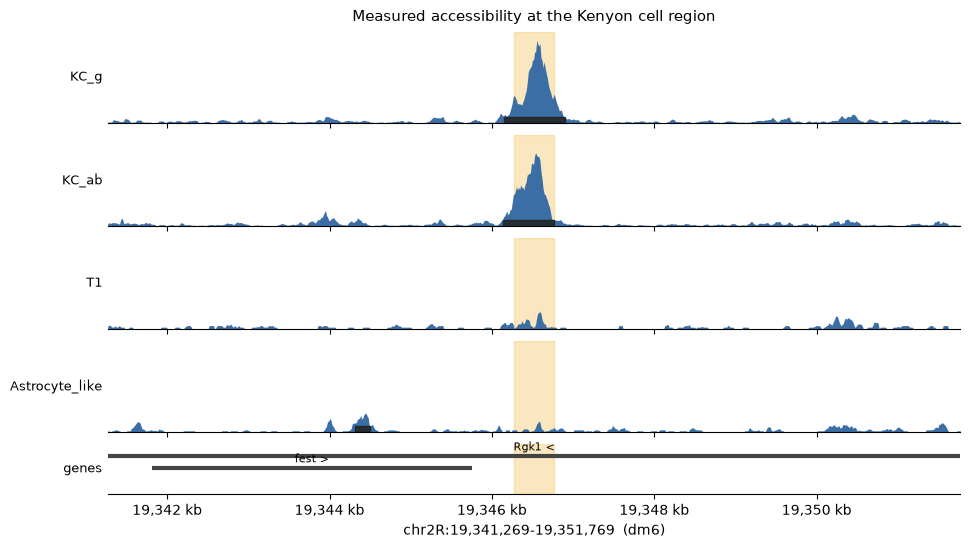

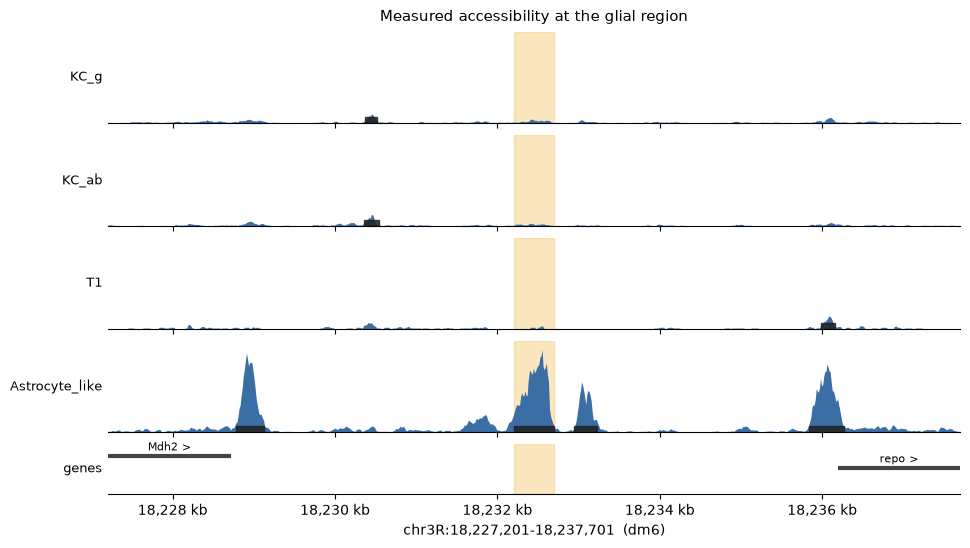

In [8]:
tracks_at(kc_region, "Measured accessibility at the Kenyon cell region")
tracks_at(glia_region, "Measured accessibility at the glial region")

## 4. Asking the model what a region is

Start with the glial region, the one near `repo`. If the model works, the
glial topics should be the tall ones.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step


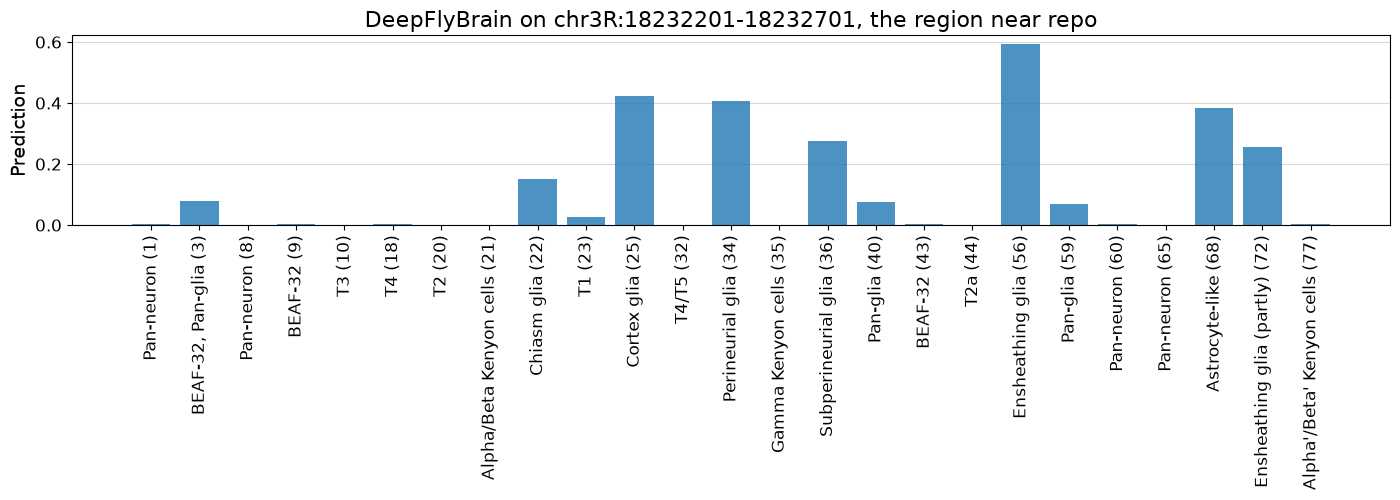

In [9]:
glia_prediction = crested.tl.predict(glia_seq, model).ravel()

crested.pl.region.bar(
    data=glia_prediction[topic_index],
    classes=topic_labels,
    title=f"DeepFlyBrain on {glia_region}, the region near repo",
    width=14, height=5, xtick_rotation=90,
)

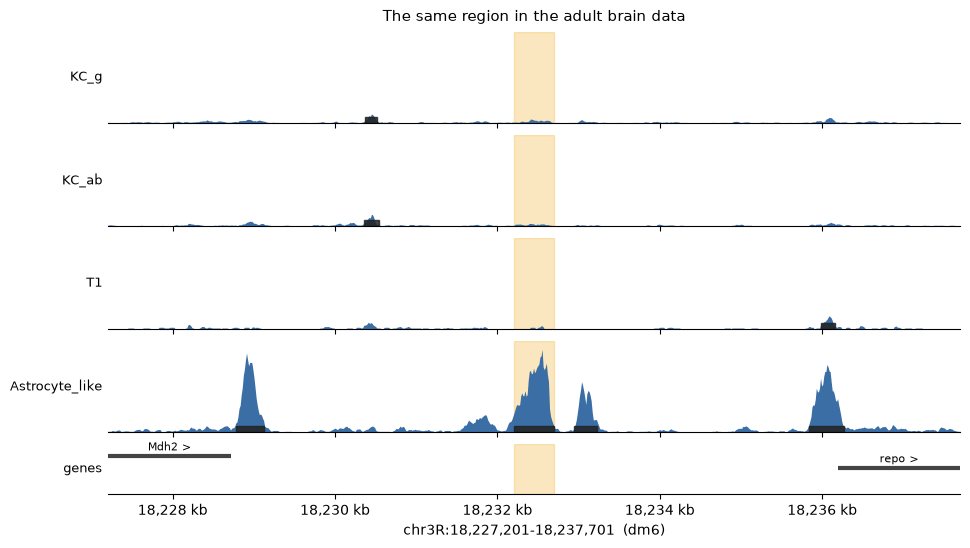

In [10]:
tracks_at(glia_region, "The same region in the adult brain data")

Every glial topic has a bar: ensheathing, cortex, perineurial, astrocyte-like,
subperineurial and chiasm glia. Every Kenyon cell and T neuron topic sits at
zero.

The model saw 500 nucleotides and nothing else, and placed the region in glia.
It says "glia" rather than "astrocyte" because glial types share much of their
regulatory programme, which is a reasonable answer rather than a failure.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step


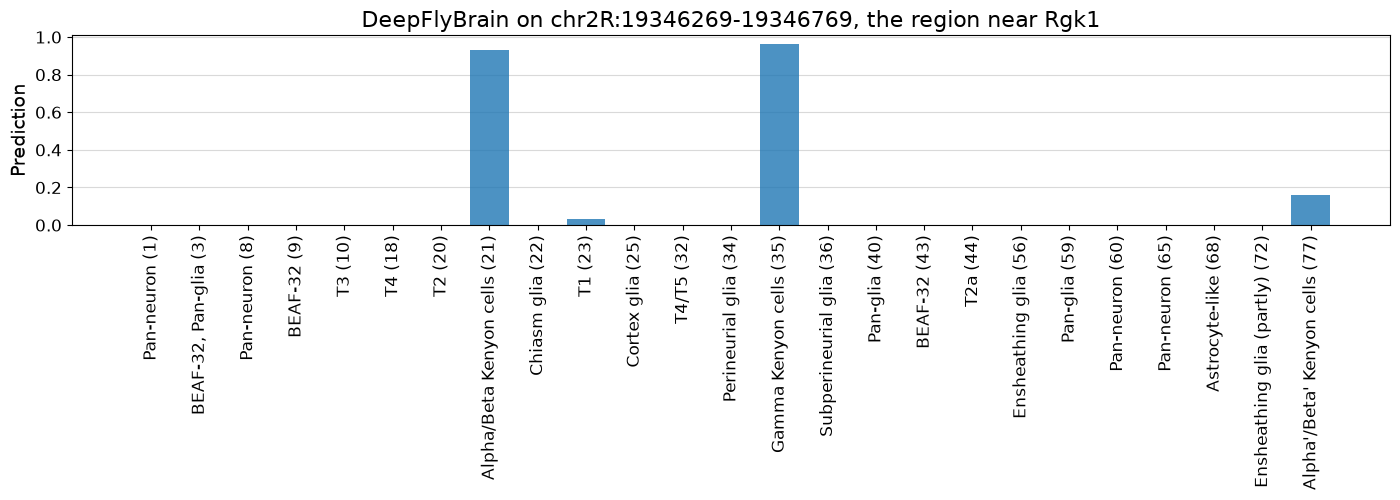

In [11]:
kc_prediction = crested.tl.predict(kc_seq, model).ravel()

crested.pl.region.bar(
    data=kc_prediction[topic_index],
    classes=topic_labels,
    title=f"DeepFlyBrain on {kc_region}, the region near Rgk1",
    width=14, height=5, xtick_rotation=90,
)

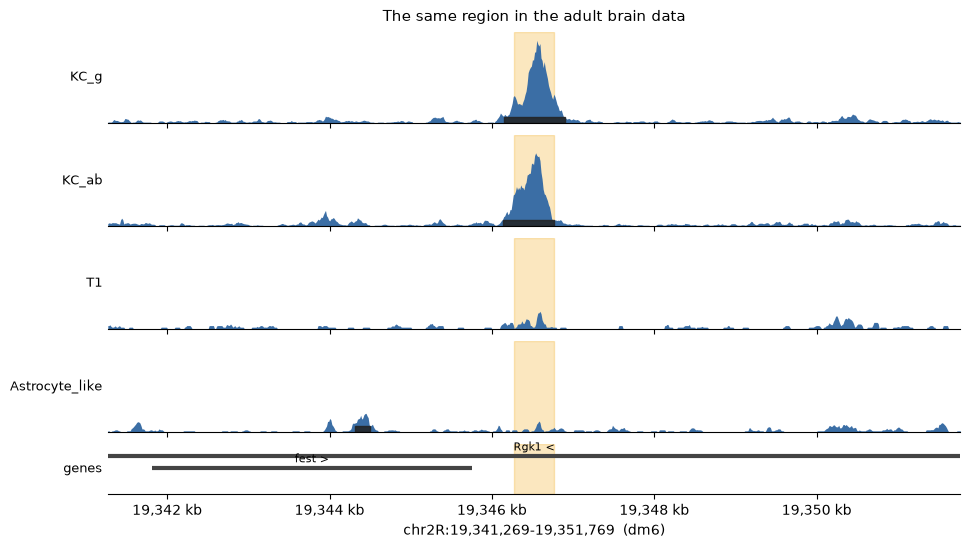

In [12]:
tracks_at(kc_region, "The same region in the adult brain data")

The pattern is inverted: Kenyon cell topics are now the tall bars, gamma Kenyon
reaching about 0.96, and the glial topics have dropped to zero. Same model, two
sequences, opposite answers.

This region sits beside `Rgk1`, one of the strongest gamma Kenyon markers in
the expression data. The gene is expressed in Kenyon cells, the
region beside it is open in Kenyon cells, and the model reaches the same
conclusion from the 500 nucleotides alone.

Count that carefully. DeepFlyBrain was trained on the accessibility data in
the tracks above, so the model agreeing with them is not independent
confirmation. The two independent measurements here are
expression and accessibility. What the model adds is different: that the
information is in the sequence.

## 5. Which nucleotides matter?

A prediction summarises all 500 nucleotides in a single number. The
contribution of each position to that number can be recovered separately.

For that we switch to regions the authors tested **in the fly**: 54 candidate
enhancers cloned in front of a reporter gene, in `enhancersTested.bed`. For an
arbitrary region we could not judge whether the model's explanation is sensible.
For these, activity was measured.

In [13]:
from scripts.download_data import janssens_tested_enhancers

tested = pd.read_csv(janssens_tested_enhancers(), sep="\t", header=None,
                     names=["chrom", "start", "end", "name"])
tested["centre"] = (tested["start"] + tested["end"]) // 2
tested["region"] = (tested["chrom"] + ":" + (tested["centre"] - 250).astype(str)
                    + "-" + (tested["centre"] + 250).astype(str))

print(len(tested), "enhancers tested in vivo")
tested.head()

Janssens et al. 2022 - enhancers tested in vivo
  already here: enhancersTested.bed (0.0 MB)
54 enhancers tested in vivo


,chrom,start,end,name,centre,region
0,chrX,18552058,18553789,enh14,18552923,chrX:18552673-18553173
1,chr3L,9525431,9526414,enh19,9525922,chr3L:9525672-9526172
2,chr2R,10442344,10442886,enh21,10442615,chr2R:10442365-10442865
3,chr2L,20050798,20051699,enh49,20051248,chr2L:20050998-20051498
4,chr3R,11450825,11451124,enh60,11450974,chr3R:11450724-11451224


Start with **enh47**, the one Figure 4 of the paper dissects. It lies near
*sNPF*, the reporter is active in gamma Kenyon cells, and the figure annotates
four transcription factor motifs in it: **Sr**, **Mef2**, **Ey** and **Onecut**.
Mutating the Ey and Mef2 sites reduces its activity.

Because the answer is known in advance, this is a fair test of the method rather
than a demonstration.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


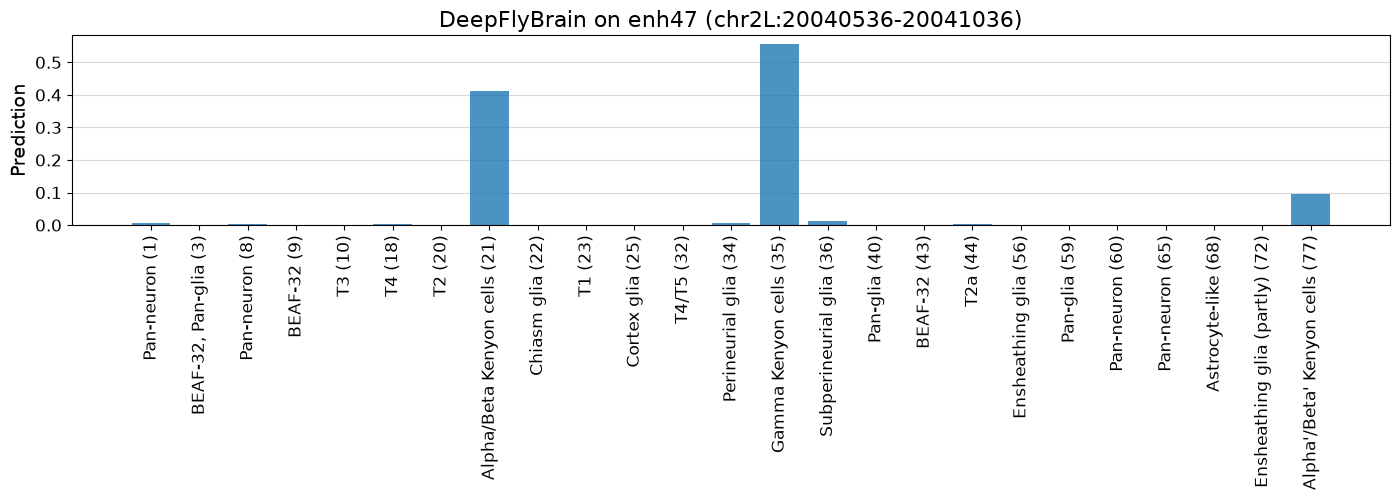

In [14]:
enh_name = "enh47"
enh_region = tested.loc[tested["name"] == enh_name, "region"].iloc[0]
enh_seq = crested.utils.fetch_sequences([enh_region], genome)[0]

crested.pl.region.bar(
    data=crested.tl.predict(enh_seq, model).ravel()[topic_index],
    classes=topic_labels,
    title=f"DeepFlyBrain on {enh_name} ({enh_region})",
    width=14, height=5, xtick_rotation=90,
)

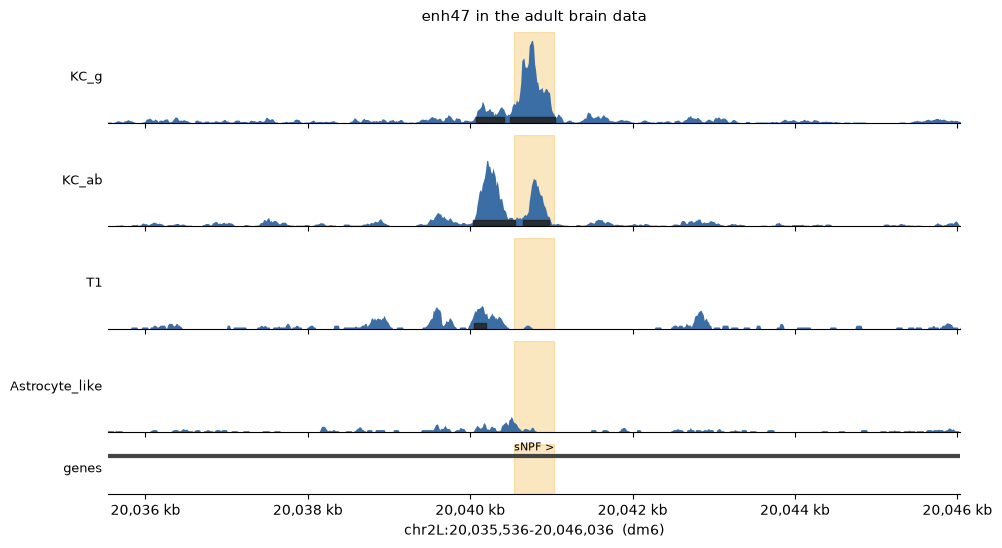

In [15]:
tracks_at(enh_region, f"{enh_name} in the adult brain data")

### Contribution scores

A **contribution score** gives every nucleotide a value: positive if it pushes
the prediction up, negative if it pushes it down. CREsted computes them with
integrated gradients in about a second.

`target_idx` chooses which of the 81 outputs to explain, counting from zero, so
`Topic_35` is index 34.

In [16]:
enh_scores, enh_onehot = crested.tl.contribution_scores(
    [enh_seq],
    target_idx=34,                  # Topic_35, gamma Kenyon cells
    model=model,
    method="integrated_grad",
    simplex_correction=True,
    genome=genome,
)

def importance(scores):
    """How much the model depends on each nucleotide, ignoring direction."""
    return np.abs(scores[0, 0]).sum(axis=1)

imp = importance(enh_scores)
print("contributions computed:", enh_scores.shape)

2026-10-28T16:21:09.937508+0100 INFO Calculating contribution scores for 1 region(s) and 1 class(es).


Model:   0%|          | 0/1 [00:00<?, ?it/s]

Model: 100%|██████████| 1/1 [00:00<00:00,  3.38it/s]

Model: 100%|██████████| 1/1 [00:00<00:00,  3.37it/s]

contributions computed: (1, 1, 500, 4)


### Which motifs are there?

CREsted ships a database of 7,446 known motifs mapped to fly transcription
factors. `scripts/motifs.py` takes a named factor and scans the sequence on both
strands.

A 500 bp sequence contains matches to something by chance, so finding a motif is
not enough. The useful question is whether a match sits where the model is
looking, so each hit is scored by how far its contribution exceeds the average
for this sequence.

In [17]:
from scripts.motifs import scan

def motifs_the_model_uses(sequence, contributions, tfs, threshold=0.75, min_ratio=1.5):
    """Motif matches that also carry above-average contribution."""
    per_base = importance(contributions)
    hits = scan(sequence, tfs, threshold=threshold)
    if not len(hits):
        return hits
    hits["x_average"] = [
        round(float(per_base[h.start:h.end].mean() / per_base.mean()), 2)
        for h in hits.itertuples()
    ]
    # Keep only sites the model actually leans on, then take each factor's best
    # sequence match among those. Doing it the other way round lets a factor
    # claim a neighbour's site: these motifs are all AT-rich and cross-match, so
    # ranking by contribution alone labelled the Mef2 site as Onecut.
    used = hits[hits["x_average"] >= min_ratio]
    return (used.sort_values("score", ascending=False)
                .drop_duplicates("tf")
                .sort_values("start")
                .reset_index(drop=True))

found = motifs_the_model_uses(enh_seq, enh_scores, ["Mef2", "ey", "sr", "onecut"])
found

,tf,start,end,strand,sequence,score,x_average
0,sr,292,299,-,GAACCCC,0.873,1.83
1,Mef2,307,318,+,CTATTAATAAA,0.970,2.53
2,ey,332,347,+,CACGCTTAATTAAGC,0.889,3.14
3,onecut,347,355,-,TATCGATT,0.985,2.09


### Marking them on the plot

`highlight_positions` draws a box at given coordinates. The plotting function
returns its figure and axes, so the transcription factor name can be written
above each box.

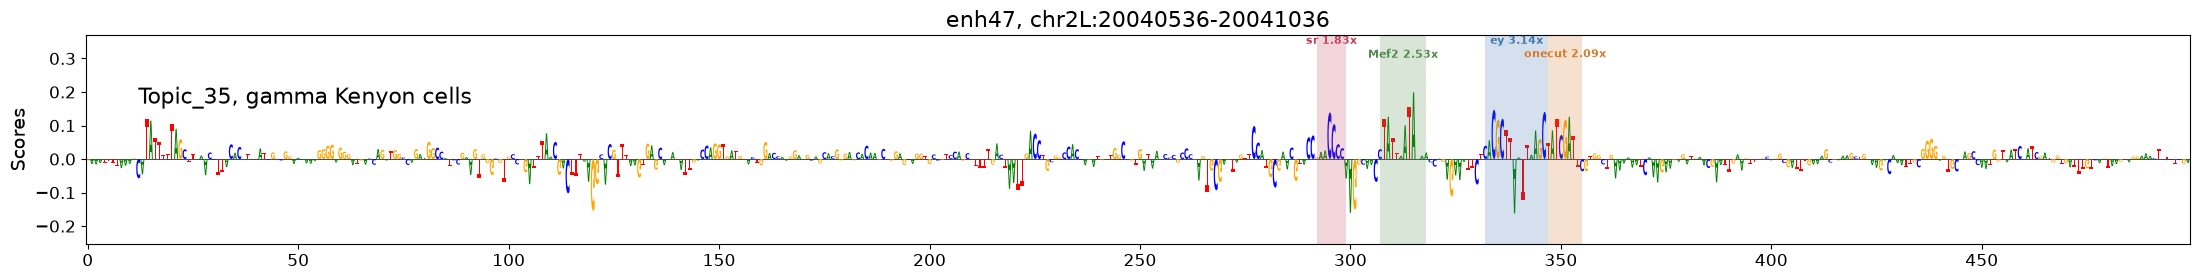

In [18]:
# One colour per transcription factor. Adjacent sites would otherwise merge
# into a single block: Ey ends at 347 and Onecut begins there. The four from
# Figure 4 keep the colours the paper gives them, so the two figures can be put
# side by side; anything else is taken from the spare list in order.
MOTIF_COLOUR = {"sr": "#C2425A", "Mef2": "#4F8A4C", "ey": "#3F76B0", "onecut": "#D97A2B"}
SPARE = ["#7A5EA8", "#1F8A8A", "#B07A1F", "#9B5B8A"]


def plot_with_motifs(scores, onehot, hits, label, class_label, width=22, height=3):
    fig, axes = crested.pl.explain.contribution_scores(
        scores, onehot,
        sequence_labels=[label], class_labels=[class_label],
        width=width, height=height, show=False,
    )
    ax = axes[0] if isinstance(axes, (list, np.ndarray)) else axes

    # Draw the boxes here rather than letting crested do it, because it takes
    # one style for all of them and we want one colour each. zorder keeps them
    # behind the nucleotides.
    colour_of = {}
    for n, tf in enumerate(dict.fromkeys(h.tf for h in hits.itertuples())):
        colour_of[tf] = MOTIF_COLOUR.get(tf, SPARE[n % len(SPARE)])
    for h in hits.itertuples():
        ax.axvspan(int(h.start), int(h.end), facecolor=colour_of[h.tf],
                   alpha=0.22, edgecolor="none", zorder=0)

    # Motifs often sit within a few nucleotides of each other, so a single row
    # of labels runs together and becomes unreadable. Draw them, measure how
    # wide each one really is, then stack any that would collide onto separate
    # rows in headroom added above the logo. The y position is given as a
    # fraction of the axis height so that changing the limits cannot move it.
    from matplotlib.backends.backend_agg import FigureCanvasAgg

    ordered = sorted(hits.itertuples(), key=lambda r: r.start)
    labels = [
        ax.text((h.start + h.end) / 2, 1.0, f"{h.tf} {h.x_average}x", ha="center",
                va="top", fontsize=8, weight="bold", color=colour_of[h.tf],
                transform=ax.get_xaxis_transform())
        for h in ordered
    ]
    fig.canvas.draw()
    # crested switches the matplotlib backend, and not every backend can
    # measure text, so fall back to one that always can.
    get = getattr(fig.canvas, "get_renderer", None)
    renderer = get() if get else FigureCanvasAgg(fig).get_renderer()

    to_data = ax.transData.inverted()
    margin = onehot.shape[-2] * 0.01          # keep a nucleotide or two clear
    rows, row_of, tallest = [], [], 0
    for text in labels:
        box = text.get_window_extent(renderer)
        left = to_data.transform((box.x0, 0))[0] - margin
        right = to_data.transform((box.x1, 0))[0] + margin
        tallest = max(tallest, box.height)
        row = 0
        while row < len(rows) and left < rows[row]:
            row += 1                           # that row is still occupied here
        if row == len(rows):
            rows.append(right)
        else:
            rows[row] = right
        row_of.append(row)

    # Free up the top of the plot so the labels never sit on the sequence.
    row_height = tallest * 1.15 / ax.get_window_extent().height
    band = min(row_height * len(rows), 0.6)
    low, high = ax.get_ylim()
    ax.set_ylim(low, low + (high - low) / (1 - band))
    for text, row in zip(labels, row_of):
        text.set_y(1.0 - row * row_height)

    plt.show()

plot_with_motifs(enh_scores, enh_onehot, found,
                 f"{enh_name}, {enh_region}", "Topic_35, gamma Kenyon cells")

All four motifs Figure 4 annotates are recovered, in the paper's order: **Sr**,
**Mef2**, **Ey**, **Onecut**. Each carries between 1.8 and 3.1 times the average
contribution for this sequence, so these are positions the model depends on. Ey
and Mef2 are the two the authors mutated, and mutating them reduced the
enhancer's activity.

A box marks where a matrix matches, and the model's signal usually runs wider
than the match. Here it continues about four nucleotides to the left of the Ey
box, into flanking sequence that no matrix accounts for. That is the normal
case: a matrix describes a core site, and the model reads its context too.

The model was never told what these motifs look like. It learned them from
accessibility data alone.

## 6. More examples

`enh47` is one of 54 enhancers the authors tested in flies, and the rest are in
the same file. Three more below, all Kenyon cell enhancers but of three
different Kenyon classes.

Each gets the three figures section 5 built up, in one go: the prediction, the
measured accessibility, and the contribution scores with motifs marked. The
topic explained is whichever annotated one the model scores highest.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


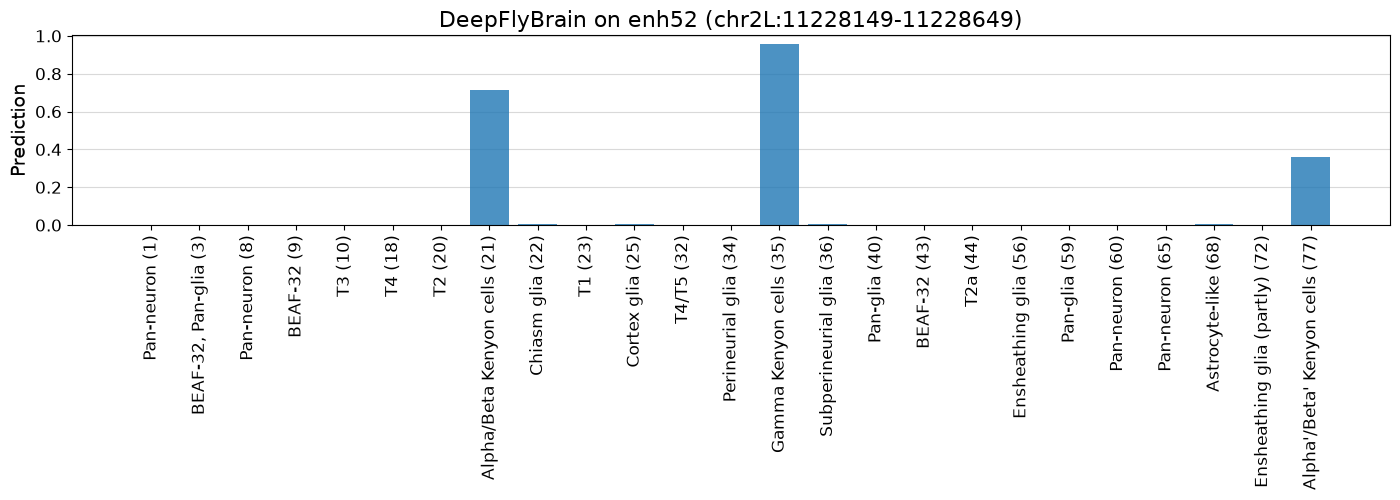

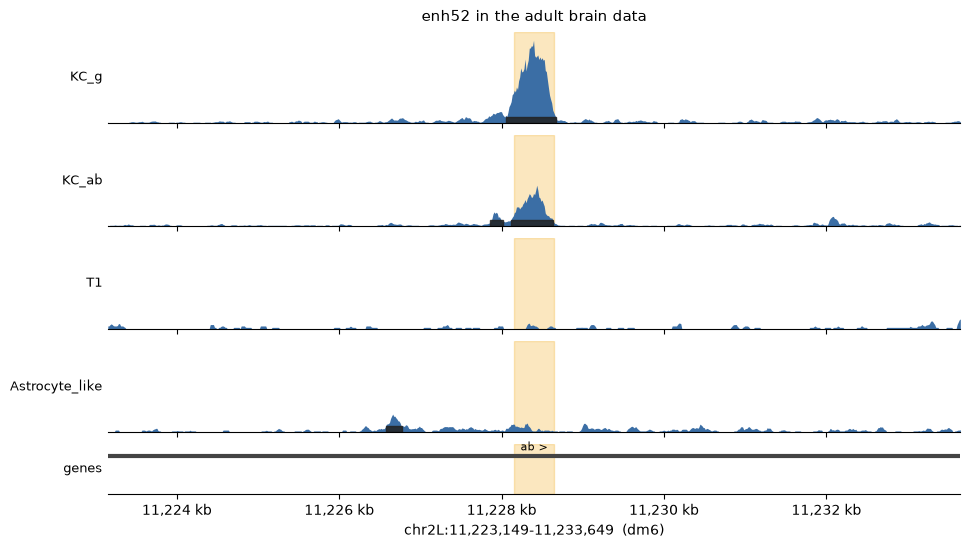

2026-10-28T16:21:28.106397+0100 INFO Calculating contribution scores for 1 region(s) and 1 class(es).


Model:   0%|          | 0/1 [00:00<?, ?it/s]

Model: 100%|██████████| 1/1 [00:00<00:00,  5.07it/s]

Model: 100%|██████████| 1/1 [00:00<00:00,  5.05it/s]

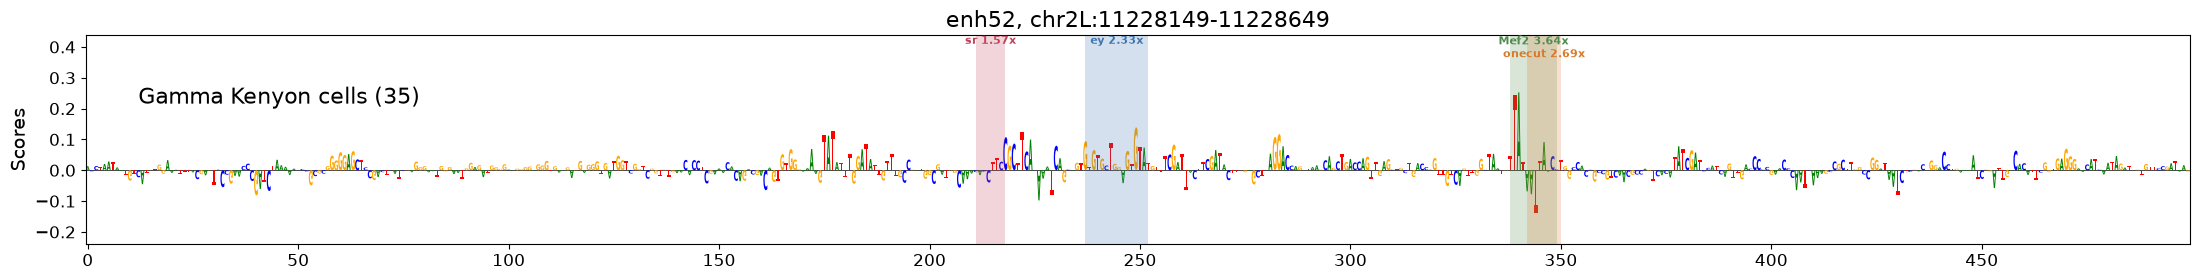

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step


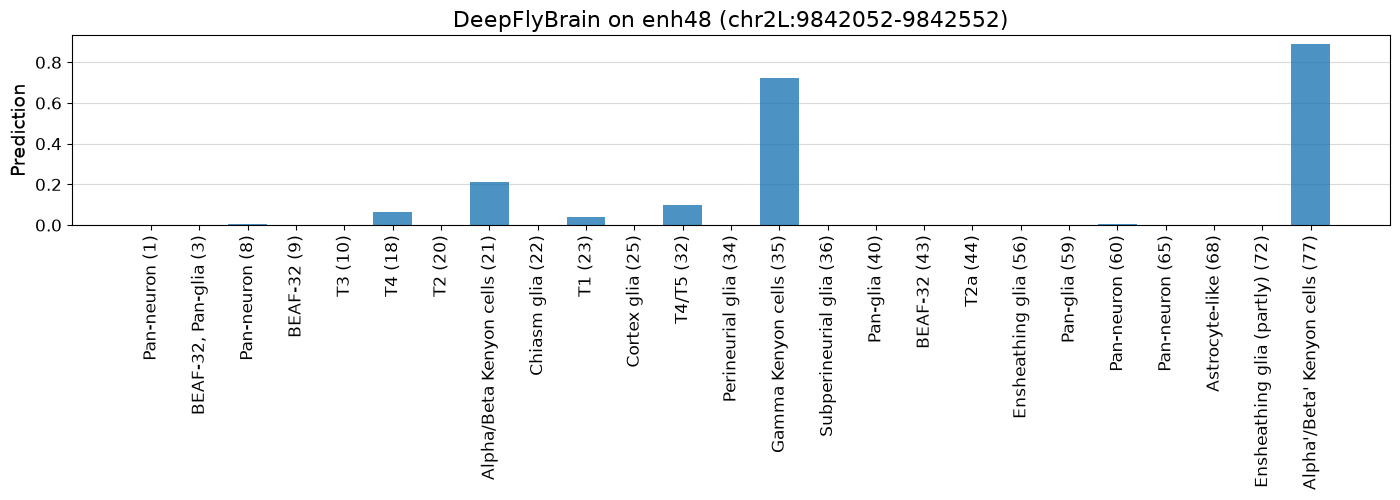

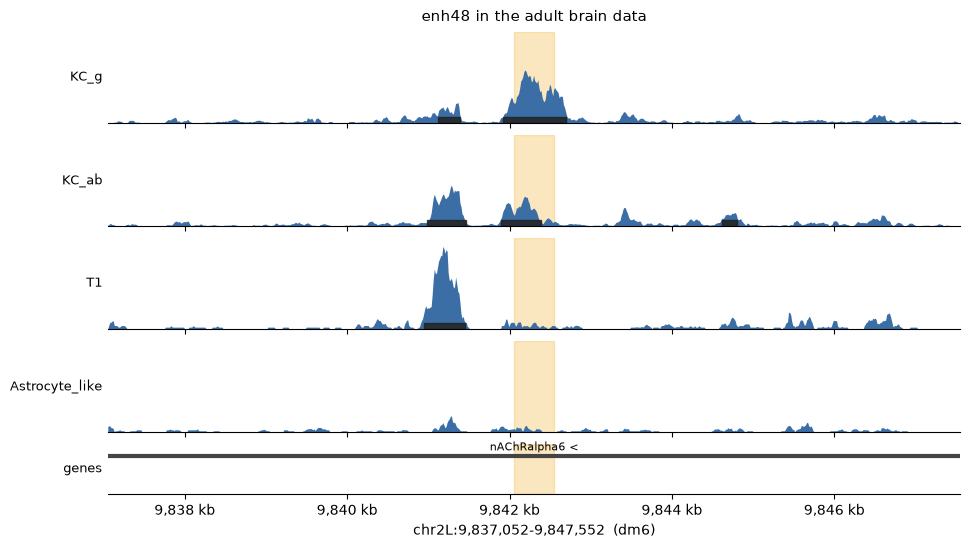

2026-10-28T16:21:44.646535+0100 INFO Calculating contribution scores for 1 region(s) and 1 class(es).


Model:   0%|          | 0/1 [00:00<?, ?it/s]

Model: 100%|██████████| 1/1 [00:00<00:00,  4.40it/s]

Model: 100%|██████████| 1/1 [00:00<00:00,  4.39it/s]

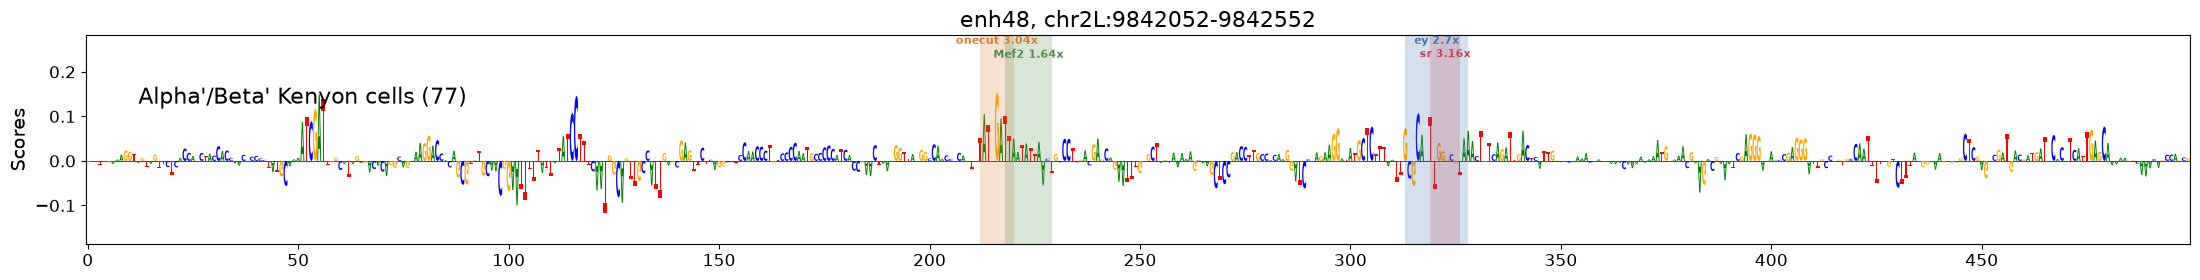

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step


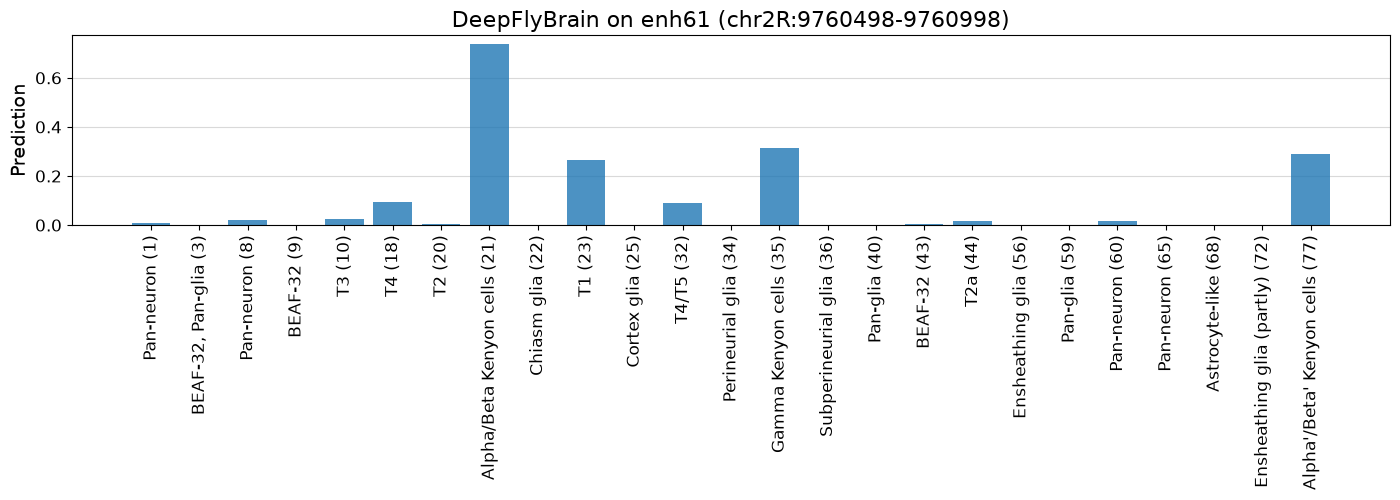

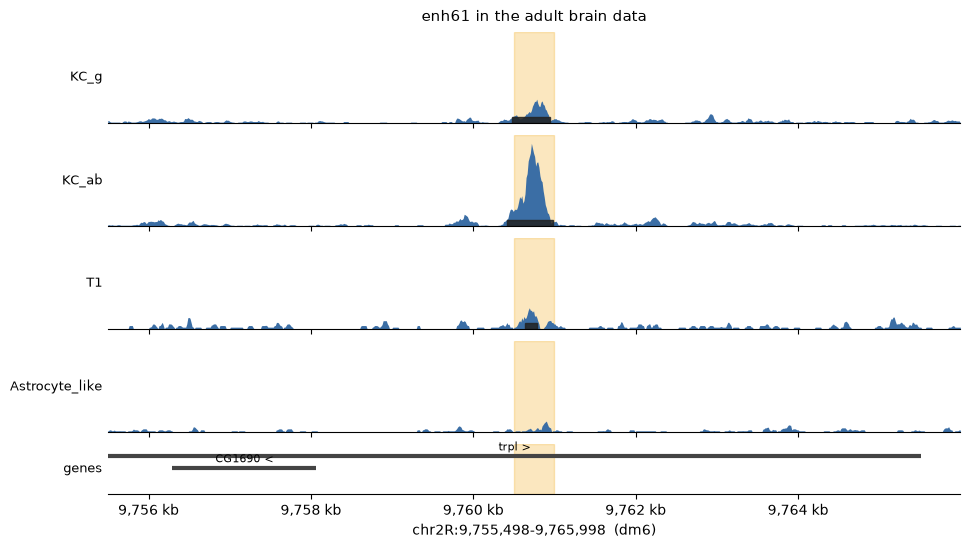

2026-10-28T16:21:58.931940+0100 INFO Calculating contribution scores for 1 region(s) and 1 class(es).


Model:   0%|          | 0/1 [00:00<?, ?it/s]

Model: 100%|██████████| 1/1 [00:00<00:00,  4.05it/s]

Model: 100%|██████████| 1/1 [00:00<00:00,  4.04it/s]

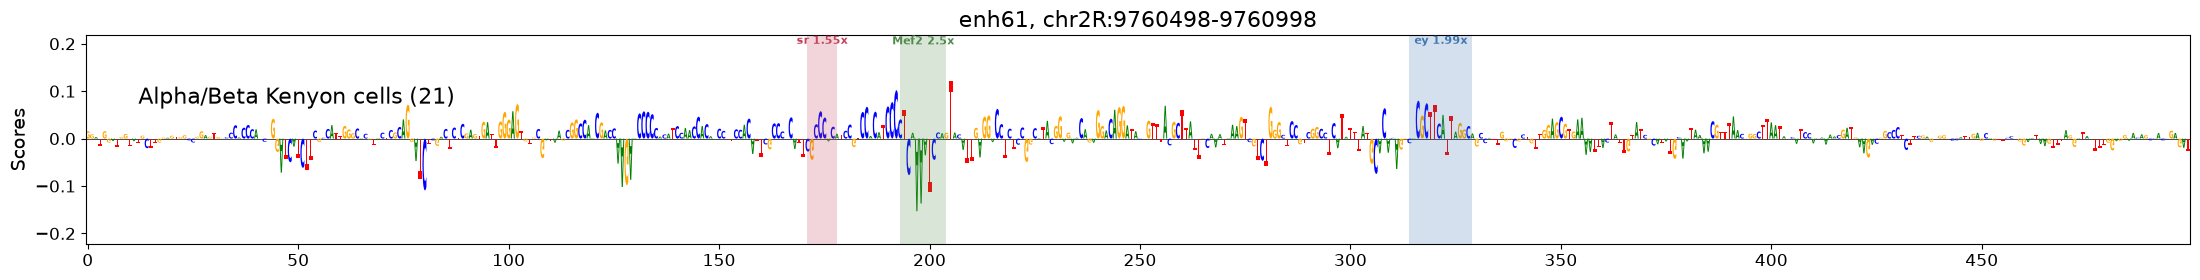

In [19]:
EXAMPLES = ["enh52", "enh48", "enh61"]       # any of the 54 names in `tested`
TFS = ["Mef2", "ey", "sr", "onecut"]         # the four from Figure 4

for name in EXAMPLES:
    region = tested.loc[tested["name"] == name, "region"].iloc[0]
    seq = crested.utils.fetch_sequences([region], genome)[0]
    prediction = crested.tl.predict(seq, model).ravel()

    # Explain the annotated topic this region scores highest on.
    k = prediction[topic_index].argmax()
    target, label = topic_index[k], topic_labels[k]

    crested.pl.region.bar(
        data=prediction[topic_index], classes=topic_labels,
        title=f"DeepFlyBrain on {name} ({region})",
        width=14, height=5, xtick_rotation=90,
    )
    tracks_at(region, f"{name} in the adult brain data")

    scores, onehot = crested.tl.contribution_scores(
        [seq], target_idx=target, model=model,
        method="integrated_grad", simplex_correction=True, genome=genome,
    )
    hits = motifs_the_model_uses(seq, scores, TFS)
    plot_with_motifs(scores, onehot, hits, f"{name}, {region}", label)

Gamma, alpha'/beta' and alpha/beta Kenyon cells: three classes of the same
kind of neuron, and the model puts each enhancer on the right one.

The same four factors turn up in all three, so what separates the classes is
not that each uses a different set of transcription factors. The scan does not
say what it is instead, and that question is open.

Note also that the factors were chosen because these are Kenyon cell
enhancers. Scanning a glial region for Kenyon factors would still return
matches, and they would mean nothing.

### Or a region of your own

Any 500 bp of dm6: the centre of a peak, 250 bp either side. To see which
nucleotides drove the answer, put it through the contribution score cells in
section 5.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step


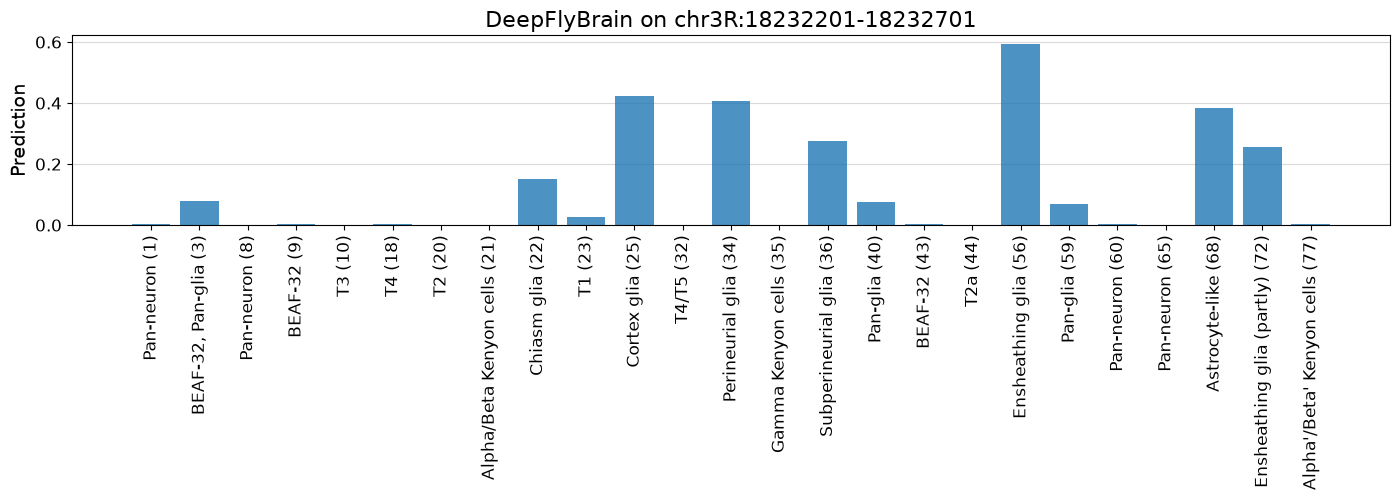

In [20]:
MY_REGION = "chr3R:18232201-18232701"     # change this

my_seq = crested.utils.fetch_sequences([MY_REGION], genome)[0]

crested.pl.region.bar(
    data=crested.tl.predict(my_seq, model).ravel()[topic_index],
    classes=topic_labels, title=f"DeepFlyBrain on {MY_REGION}",
    width=14, height=5, xtick_rotation=90,
)

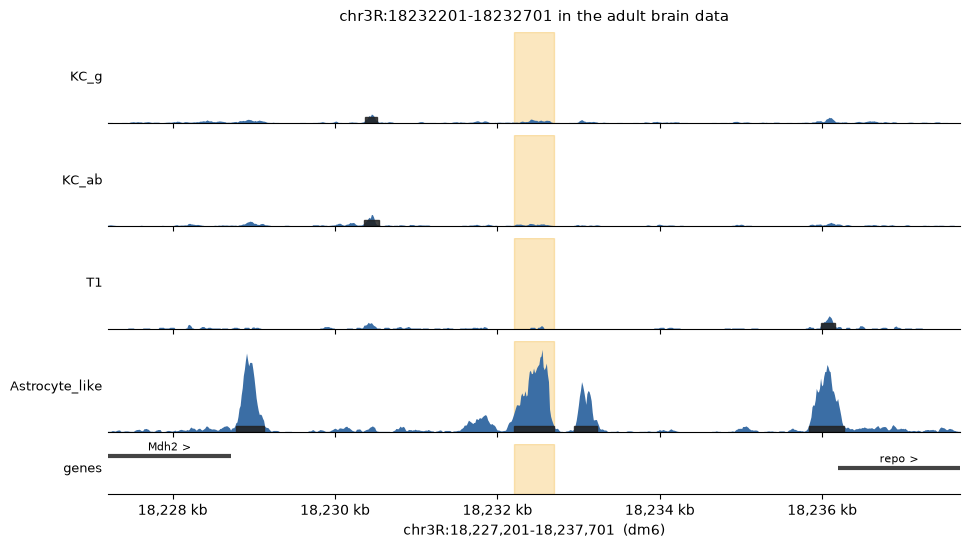

In [21]:
tracks_at(MY_REGION, f"{MY_REGION} in the adult brain data")

Questions to ask about your plots:

- Are any bars tall? If everything is near zero, the model does not
  recognise the region
- Do the tall bars agree with the cell type whose track carries the peak in
  the coverage figure above?

## 7. What this model cannot do

- **It knows only the cells it was trained on.** There is no dopaminergic
  class, and it never saw a larval brain
- **Most of the 81 topics are unannotated.** A confident prediction for one of
  those cannot be read
- **It reports resemblance, not causation.** Showing that a region is an
  enhancer needs the experiment: clone the 500 bp in front of a reporter and
  look at the fly
- **Contribution scores are the model's reasoning, not the cell's**

## Summary

You gave 500 bp of DNA to a pretrained network and asked which cell type it
belongs to and which nucleotides decided that. On an enhancer the authors had
dissected in flies, the model leaned on the sites they had mutated, without ever
having been told what those sites look like.

Everything here was two calls: `crested.tl.predict` for what a region is, and
`crested.tl.contribution_scores` for which nucleotides said so. Both work the
same way on any region of dm6 and on any of the pretrained models CREsted
offers.